# Лабораторная работа №5. Градиентный бустинг

**Цель:** исследовать алгоритм градиентного бустинга в задачах классификации и регрессии, сравнить базовые и улучшенные модели `sklearn` с собственной реализацией

Используем те же наборы данных, что и в предыдущих лабораторных работах:
- **Breast Cancer Wisconsin (Diagnostic)** - бинарная классификация (`0` - malignant, `1` - benign).
- **Wine Quality Red** - регрессия целевой переменной `quality`

Для воспроизводимости используется разбиение 80/20 с `random_state=42`. Для классификации применяется стратификация. Подбор параметров выполняется только на обучающей выборке

## 1. Импорт библиотек и настройка эксперимента

Подключаем инструменты для работы с данными, обучения моделей, подбора гиперпараметров и оценки качества. Фиксируем random seed для воспроизводимости

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, KFold
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score, recall_score,
    confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score,
    RocCurveDisplay
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.4.6
Pandas: 3.0.5


## 2. Загрузка и первичный анализ данных

Загружаем Breast Cancer из `sklearn`, а Wine Quality Red - из UCI. Для Wine Quality используется публичный CSV-файл UCI. Если в вашей среде нет доступа к интернету, скачайте `winequality-red.csv` и положите его рядом с ноутбуком

In [2]:
cancer = load_breast_cancer(as_frame=True)
X_clf = cancer.data.copy()
y_clf = cancer.target.copy()

print("Breast Cancer:", X_clf.shape)
print("Распределение классов:")
print(y_clf.value_counts().sort_index().rename(index={0: "malignant", 1: "benign"}))


wine_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
try:
    wine = pd.read_csv(wine_url, sep=";")
except Exception as exc:
    raise RuntimeError(
        "Не удалось загрузить Wine Quality Red. Скачайте winequality-red.csv "
        "с UCI и замените wine_url на локальный путь к файлу."
    ) from exc

X_reg = wine.drop(columns="quality")
y_reg = wine["quality"]

print("\nWine Quality:", X_reg.shape)
display(wine.head())
display(wine.describe().T)

Breast Cancer: (569, 30)
Распределение классов:
target
malignant    212
benign       357
Name: count, dtype: int64

Wine Quality: (1599, 11)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


## 3. Разделение на обучающую и тестовую выборки

Тестовые данные не используются при подборе параметров. Для классификации сохраняем пропорции классов с помощью `stratify`

In [3]:
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=RANDOM_STATE, stratify=y_clf
)

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE
)

print("Classification:", X_train_clf.shape, X_test_clf.shape)
print("Regression:", X_train_reg.shape, X_test_reg.shape)

Classification: (455, 30) (114, 30)
Regression: (1279, 11) (320, 11)


## 4. Функции оценки качества

Для классификации используем Accuracy, F1-score, ROC-AUC, Recall и F1 для класса malignant. Отдельное внимание уделяется Recall класса malignant, поскольку пропуск злокачественной опухоли особенно нежелателен. Для Wine Quality используем MAE, RMSE и R^2

In [4]:
def evaluate_classifier(model, X_test, y_test, name="model"):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    return {
        "Модель": name,
        "Accuracy": accuracy_score(y_test, pred),
        "F1 binary (benign)": f1_score(y_test, pred, average="binary"),
        "F1 macro": f1_score(y_test, pred, average="macro"),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "Recall malignant": recall_score(y_test, pred, pos_label=0),
        "F1 malignant": f1_score(y_test, pred, pos_label=0)
    }


def evaluate_regressor(model, X_test, y_test, name="model"):
    pred = model.predict(X_test)
    return {
        "Модель": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": mean_squared_error(y_test, pred) ** 0.5,
        "R^2": r2_score(y_test, pred)
    }

## 5. Baseline: Gradient Boosting из sklearn - классификация

Обучаем классификатор с умеренными параметрами по умолчанию. Деревьям решений не требуется стандартизация признаков: разбиения зависят от порядка значений, а не от масштаба

In [5]:
gb_clf_baseline = GradientBoostingClassifier(random_state=RANDOM_STATE)
gb_clf_baseline.fit(X_train_clf, y_train_clf)

clf_baseline_results = evaluate_classifier(
    gb_clf_baseline, X_test_clf, y_test_clf, "sklearn baseline"
)
display(pd.DataFrame([clf_baseline_results]).round(4))
print(classification_report(
    y_test_clf, gb_clf_baseline.predict(X_test_clf),
    target_names=["malignant", "benign"], zero_division=0
))

,Модель,Accuracy,F1 binary (benign),F1 macro,ROC-AUC,Recall malignant,F1 malignant
0,sklearn baseline,0.9561,0.966,0.9521,0.9907,0.9048,0.9383


              precision    recall  f1-score   support

   malignant       0.97      0.90      0.94        42
      benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



## 6. Анализ baseline-классификатора

Строим матрицу ошибок и ROC-кривую. Эти графики позволяют оценить не только общую точность, но и характер ошибок классификации

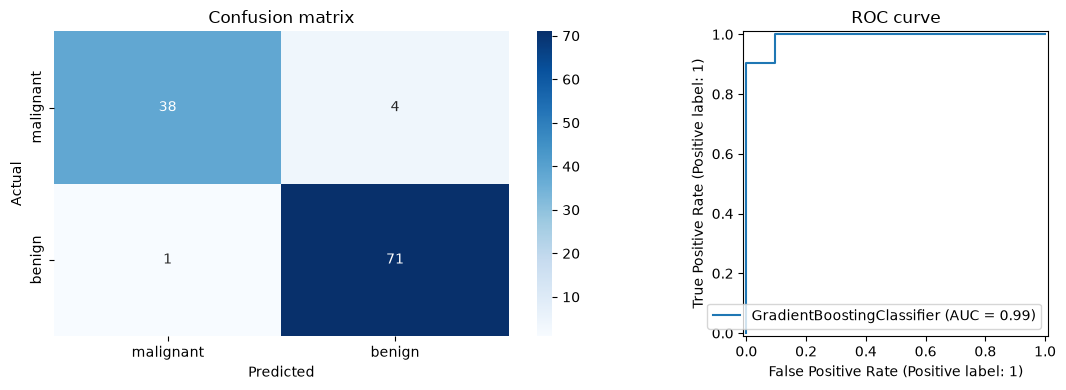

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

cm = confusion_matrix(y_test_clf, gb_clf_baseline.predict(X_test_clf))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["malignant", "benign"],
    yticklabels=["malignant", "benign"], ax=axes[0]
)
axes[0].set_title("Confusion matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

RocCurveDisplay.from_estimator(gb_clf_baseline, X_test_clf, y_test_clf, ax=axes[1])
axes[1].set_title("ROC curve")

plt.tight_layout()
plt.show()

## 7. Улучшение baseline классификации: подбор гиперпараметров

Проверяем влияние числа деревьев, скорости обучения, глубины базовых деревьев и минимального числа объектов в листе. Выбор лучшей конфигурации выполняется по среднему macro F1 на стратифицированной кросс-валидации

In [7]:
clf_param_grid = {
    "n_estimators": [50, 100, 150],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [1, 2, 3],
    "min_samples_leaf": [1, 2, 4],
    "subsample": [0.8, 1.0]
}

clf_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
clf_search = GridSearchCV(
    GradientBoostingClassifier(random_state=RANDOM_STATE),
    param_grid=clf_param_grid,
    scoring="f1_macro",
    cv=clf_cv,
    n_jobs=-1,
    verbose=1
)
clf_search.fit(X_train_clf, y_train_clf)

print("Лучшие параметры:", clf_search.best_params_)
print("Лучший CV macro F1:", round(clf_search.best_score_, 4))

gb_clf_improved = clf_search.best_estimator_
clf_improved_results = evaluate_classifier(
    gb_clf_improved, X_test_clf, y_test_clf, "sklearn improved"
)
display(pd.DataFrame([clf_baseline_results, clf_improved_results]).round(4))

Fitting 5 folds for each of 162 candidates, totalling 810 fits
Лучшие параметры: {'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 4, 'n_estimators': 150, 'subsample': 0.8}
Лучший CV macro F1: 0.9718


,Модель,Accuracy,F1 binary (benign),F1 macro,ROC-AUC,Recall malignant,F1 malignant
0,sklearn baseline,0.9561,0.9660,0.9521,0.9907,0.9048,0.9383
1,sklearn improved,0.9474,0.9589,0.9429,0.9934,0.9048,0.9268


## 8. Baseline: Gradient Boosting из sklearn - регрессия

Обучаем регрессор на Wine Quality Red. В качестве baseline используем стандартные параметры `GradientBoostingRegressor`

In [8]:
gb_reg_baseline = GradientBoostingRegressor(random_state=RANDOM_STATE)
gb_reg_baseline.fit(X_train_reg, y_train_reg)

reg_baseline_results = evaluate_regressor(
    gb_reg_baseline, X_test_reg, y_test_reg, "sklearn baseline"
)
display(pd.DataFrame([reg_baseline_results]).round(4))

,Модель,MAE,RMSE,R^2
0,sklearn baseline,0.4849,0.6019,0.4456


## 9. Анализ baseline-регрессора

Сравниваем истинные и предсказанные значения, а также анализируем распределение остатков. Это помогает выявить систематическое смещение и крупные ошибки

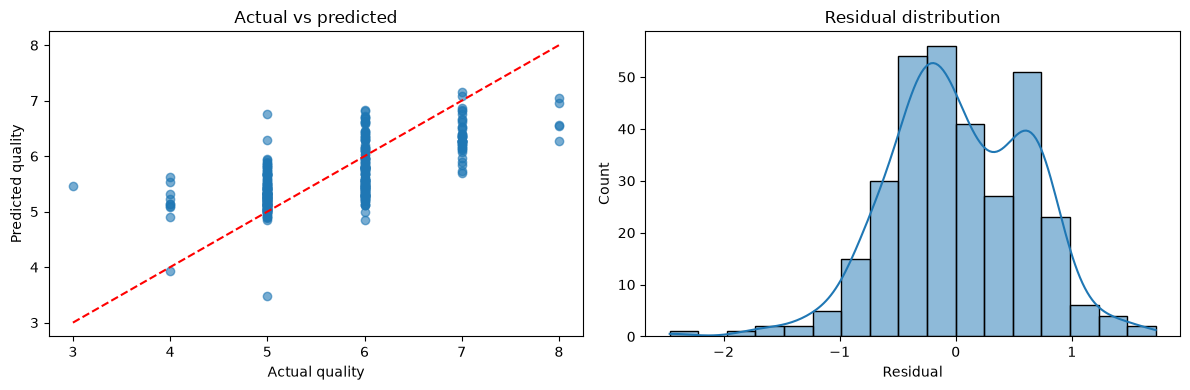

In [9]:
reg_pred_baseline = gb_reg_baseline.predict(X_test_reg)
residuals = y_test_reg - reg_pred_baseline

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_test_reg, reg_pred_baseline, alpha=0.6)
axes[0].plot(
    [y_test_reg.min(), y_test_reg.max()],
    [y_test_reg.min(), y_test_reg.max()], "r--"
)
axes[0].set_title("Actual vs predicted")
axes[0].set_xlabel("Actual quality")
axes[0].set_ylabel("Predicted quality")

sns.histplot(residuals, kde=True, ax=axes[1])
axes[1].set_title("Residual distribution")
axes[1].set_xlabel("Residual")

plt.tight_layout()
plt.show()

## 10. Улучшение baseline регрессии: подбор гиперпараметров

Используем 5-fold кросс-валидацию и минимизируем MAE. Подбор проводится только на обучающей выборке; тестовая выборка остаётся независимой оценкой итогового качества

In [10]:
reg_param_grid = {
    "n_estimators": [50, 100, 150],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [1, 2, 3],
    "min_samples_leaf": [1, 2, 4],
    "subsample": [0.8, 1.0],
    "loss": ["squared_error", "huber"]
}

reg_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
reg_search = GridSearchCV(
    GradientBoostingRegressor(random_state=RANDOM_STATE),
    param_grid=reg_param_grid,
    scoring="neg_mean_absolute_error",
    cv=reg_cv,
    n_jobs=-1,
    verbose=1
)
reg_search.fit(X_train_reg, y_train_reg)

print("Лучшие параметры:", reg_search.best_params_)
print("Лучший CV MAE:", round(-reg_search.best_score_, 4))

gb_reg_improved = reg_search.best_estimator_
reg_improved_results = evaluate_regressor(
    gb_reg_improved, X_test_reg, y_test_reg, "sklearn improved"
)
display(pd.DataFrame([reg_baseline_results, reg_improved_results]).round(4))

Fitting 5 folds for each of 324 candidates, totalling 1620 fits
Лучшие параметры: {'learning_rate': 0.1, 'loss': 'huber', 'max_depth': 3, 'min_samples_leaf': 2, 'n_estimators': 150, 'subsample': 1.0}
Лучший CV MAE: 0.4743


,Модель,MAE,RMSE,R^2
0,sklearn baseline,0.4849,0.6019,0.4456
1,sklearn improved,0.4676,0.5844,0.4773


## 11. Собственная реализация градиентного бустинга для регрессии

Реализуем упрощённый градиентный бустинг для квадратичной функции потерь. Начальное предсказание - среднее целевой переменной. На каждом шаге дерево регрессии обучается предсказывать остатки, после чего его прогноз с коэффициентом `learning_rate` добавляется к текущему ансамблю

Т.к. это учебная реализация для числовой регрессии, она намеренно не использует `GradientBoostingRegressor` внутри

In [11]:
class MyGradientBoostingRegressor:
    def __init__(self, n_estimators=100, learning_rate=0.05,
                 max_depth=2, min_samples_leaf=2, random_state=42):
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.random_state = random_state
        self.trees_ = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self.init_ = float(np.mean(y))
        current = np.full(y.shape[0], self.init_, dtype=float)
        self.trees_ = []

        for i in range(self.n_estimators):
            residual = y - current
            tree = DecisionTreeRegressor(
                max_depth=self.max_depth,
                min_samples_leaf=self.min_samples_leaf,
                random_state=self.random_state + i
            )
            tree.fit(X, residual)
            update = tree.predict(X)
            current += self.learning_rate * update
            self.trees_.append(tree)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        pred = np.full(X.shape[0], self.init_, dtype=float)
        for tree in self.trees_:
            pred += self.learning_rate * tree.predict(X)
        return pred

## 12. Обучение и проверка собственной модели регрессии

Сначала обучаем собственную модель с базовой конфигурацией, затем переносим в неё гиперпараметры, найденные для `sklearn`. Такое сравнение показывает, насколько близко учебная реализация воспроизводит поведение библиотечной модели

In [12]:
my_gbr_raw = MyGradientBoostingRegressor(
    n_estimators=100, learning_rate=0.05, max_depth=2,
    min_samples_leaf=2, random_state=RANDOM_STATE
)
my_gbr_raw.fit(X_train_reg, y_train_reg)

best_reg_params = reg_search.best_params_.copy()
my_gbr_improved = MyGradientBoostingRegressor(
    n_estimators=best_reg_params["n_estimators"],
    learning_rate=best_reg_params["learning_rate"],
    max_depth=best_reg_params["max_depth"],
    min_samples_leaf=best_reg_params["min_samples_leaf"],
    random_state=RANDOM_STATE
)
my_gbr_improved.fit(X_train_reg, y_train_reg)

my_reg_raw_results = evaluate_regressor(
    my_gbr_raw, X_test_reg, y_test_reg, "MyGradientBoosting raw"
)
my_reg_improved_results = evaluate_regressor(
    my_gbr_improved, X_test_reg, y_test_reg, "MyGradientBoosting improved"
)
display(pd.DataFrame([
    reg_baseline_results, reg_improved_results,
    my_reg_raw_results, my_reg_improved_results
]).round(4))

,Модель,MAE,RMSE,R^2
0,sklearn baseline,0.4849,0.6019,0.4456
1,sklearn improved,0.4676,0.5844,0.4773
2,MyGradientBoosting raw,0.5002,0.6194,0.4129
3,MyGradientBoosting improved,0.4815,0.6005,0.4482


## 13. Собственная реализация градиентного бустинга для классификации

Для бинарной классификации используем логистическую функцию потерь. Модель хранит текущие логиты, на каждом шаге вычисляет отрицательный градиент `y - p`, обучает дерево регрессии на этом псевдоостатке и обновляет логиты. Вероятность положительного класса получается применением сигмоиды

Это градиентный шаг по функциональному пространству; в отличие от полного Newton boosting, здесь не используется деление на вторую производную

In [13]:
class MyGradientBoostingClassifier:
    def __init__(self, n_estimators=100, learning_rate=0.05,
                 max_depth=2, min_samples_leaf=2, random_state=42):
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.random_state = random_state
        self.trees_ = []

    @staticmethod
    def _sigmoid(z):
        z = np.clip(z, -35, 35)
        return 1.0 / (1.0 + np.exp(-z))

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        if set(np.unique(y)) != {0.0, 1.0}:
            raise ValueError("MyGradientBoostingClassifier ожидает метки классов 0 и 1.")

        p0 = np.clip(np.mean(y), 1e-6, 1 - 1e-6)
        self.init_ = float(np.log(p0 / (1 - p0)))
        raw = np.full(y.shape[0], self.init_, dtype=float)
        self.trees_ = []

        for i in range(self.n_estimators):
            prob = self._sigmoid(raw)
            pseudo_residual = y - prob
            tree = DecisionTreeRegressor(
                max_depth=self.max_depth,
                min_samples_leaf=self.min_samples_leaf,
                random_state=self.random_state + i
            )
            tree.fit(X, pseudo_residual)
            raw += self.learning_rate * tree.predict(X)
            self.trees_.append(tree)
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        raw = np.full(X.shape[0], self.init_, dtype=float)
        for tree in self.trees_:
            raw += self.learning_rate * tree.predict(X)
        p1 = self._sigmoid(raw)
        return np.column_stack([1 - p1, p1])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

## 14. Обучение и проверка собственной модели классификации

Сравниваем собственную реализацию в исходной конфигурации и с основными параметрами, найденными GridSearchCV. В данном варианте сохраняем бинарную кодировку sklearn: `0` - malignant, `1` - benign

In [14]:
my_gbc_raw = MyGradientBoostingClassifier(
    n_estimators=100, learning_rate=0.05, max_depth=2,
    min_samples_leaf=2, random_state=RANDOM_STATE
)
my_gbc_raw.fit(X_train_clf, y_train_clf)

best_clf_params = clf_search.best_params_.copy()
my_gbc_improved = MyGradientBoostingClassifier(
    n_estimators=best_clf_params["n_estimators"],
    learning_rate=best_clf_params["learning_rate"],
    max_depth=best_clf_params["max_depth"],
    min_samples_leaf=best_clf_params["min_samples_leaf"],
    random_state=RANDOM_STATE
)
my_gbc_improved.fit(X_train_clf, y_train_clf)

my_clf_raw_results = evaluate_classifier(
    my_gbc_raw, X_test_clf, y_test_clf, "MyGradientBoosting raw"
)
my_clf_improved_results = evaluate_classifier(
    my_gbc_improved, X_test_clf, y_test_clf, "MyGradientBoosting improved"
)
display(pd.DataFrame([
    clf_baseline_results, clf_improved_results,
    my_clf_raw_results, my_clf_improved_results
]).round(4))

,Модель,Accuracy,F1 binary (benign),F1 macro,ROC-AUC,Recall malignant,F1 malignant
0,sklearn baseline,0.9561,0.9660,0.9521,0.9907,0.9048,0.9383
1,sklearn improved,0.9474,0.9589,0.9429,0.9934,0.9048,0.9268
2,MyGradientBoosting raw,0.9298,0.9444,0.9246,0.9904,0.9048,0.9048
3,MyGradientBoosting improved,0.9211,0.9371,0.9156,0.9759,0.9048,0.8941


## 15. Проверка корректности собственной реализации

Проверяем размерности предсказаний, диапазон вероятностей и то, что сумма вероятностей двух классов равна единице. Эти проверки не заменяют оценку качества на отложенной выборке, но помогают обнаружить ошибки реализации

In [15]:
proba_check = my_gbc_improved.predict_proba(X_test_clf)
pred_check = my_gbc_improved.predict(X_test_clf)
reg_pred_check = my_gbr_improved.predict(X_test_reg)

assert proba_check.shape == (len(X_test_clf), 2)
assert pred_check.shape == (len(X_test_clf),)
assert reg_pred_check.shape == (len(X_test_reg),)
assert np.all((proba_check >= 0) & (proba_check <= 1))
assert np.allclose(proba_check.sum(axis=1), 1.0, atol=1e-7)
assert np.isfinite(reg_pred_check).all()

print("Проверки пройдены.")
print("Форма predict_proba:", proba_check.shape)
print("Минимальная/максимальная сумма вероятностей:",
      proba_check.sum(axis=1).min(), proba_check.sum(axis=1).max())

Проверки пройдены.
Форма predict_proba: (114, 2)
Минимальная/максимальная сумма вероятностей: 1.0 1.0


## 16. Сводное сравнение моделей ЛР5

Собираем метрики всех вариантов в таблицы. Для классификации F1 binary относится к классу `1` (benign), а метрики malignant вынесены отдельно

In [16]:
clf_results_all = pd.DataFrame([
    clf_baseline_results, clf_improved_results,
    my_clf_raw_results, my_clf_improved_results
])
reg_results_all = pd.DataFrame([
    reg_baseline_results, reg_improved_results,
    my_reg_raw_results, my_reg_improved_results
])

print("КЛАССИФИКАЦИЯ")
display(clf_results_all.set_index("Модель").round(4))
print("РЕГРЕССИЯ")
display(reg_results_all.set_index("Модель").round(4))

КЛАССИФИКАЦИЯ


,Accuracy,F1 binary (benign),F1 macro,ROC-AUC,Recall malignant,F1 malignant
Модель,,,,,,
sklearn baseline,0.9561,0.9660,0.9521,0.9907,0.9048,0.9383
sklearn improved,0.9474,0.9589,0.9429,0.9934,0.9048,0.9268
MyGradientBoosting raw,0.9298,0.9444,0.9246,0.9904,0.9048,0.9048
MyGradientBoosting improved,0.9211,0.9371,0.9156,0.9759,0.9048,0.8941


РЕГРЕССИЯ


,MAE,RMSE,R^2
Модель,,,
sklearn baseline,0.4849,0.6019,0.4456
sklearn improved,0.4676,0.5844,0.4773
MyGradientBoosting raw,0.5002,0.6194,0.4129
MyGradientBoosting improved,0.4815,0.6005,0.4482


## 17. Важность признаков улучшенных sklearn-моделей

Градиентный бустинг позволяет оценить вклад признаков в построение ансамбля. Важность признаков не показывает причинно-следственную связь и может быть смещена в пользу признаков с большим числом возможных разбиений

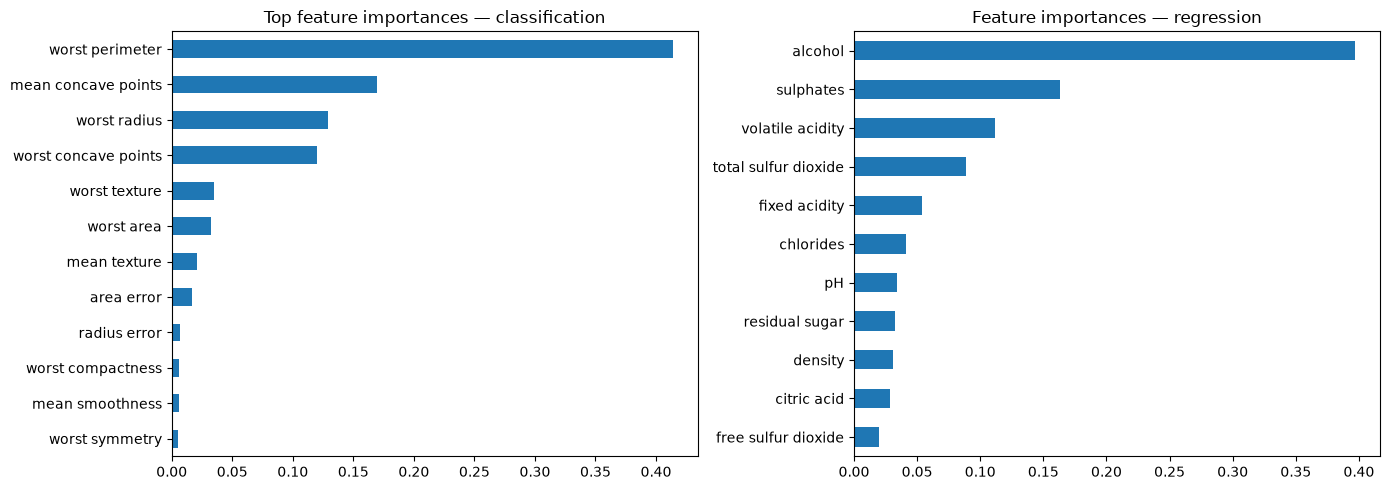

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

clf_importance = pd.Series(
    gb_clf_improved.feature_importances_, index=X_train_clf.columns
).sort_values().tail(12)
clf_importance.plot(kind="barh", ax=axes[0])
axes[0].set_title("Top feature importances — classification")

reg_importance = pd.Series(
    gb_reg_improved.feature_importances_, index=X_train_reg.columns
).sort_values()
reg_importance.plot(kind="barh", ax=axes[1])
axes[1].set_title("Feature importances — regression")

plt.tight_layout()
plt.show()

## 18. Итоговое сравнение алгоритмов ЛР1-ЛР5

В этом разделе фиксируются лучшие результаты каждого алгоритма из предыдущих лабораторных. Значения ЛР1-ЛР4 приведены по уже полученным результатам проекта; после выполнения текущего ноутбука заполните строку ЛР5 по метрикам улучшенных моделей (или замените её результатами собственной реализации, если в итоговой работе сравниваются именно они)

Для честного сравнения необходимо использовать одинаковые датасеты, разбиение train/test и определения метрик. Если в отдельных лабораторных использовались разные настройки или разбиения, это следует отметить в выводах

In [18]:
comparison_classification = pd.DataFrame([
    {"Алгоритм": "KNN (ЛР1)", "Accuracy": 0.9737, "F1": 0.9796, "ROC-AUC": 0.9884},
    {"Алгоритм": "Logistic Regression (ЛР2)", "Accuracy": 0.9825, "F1": 0.9861, "ROC-AUC": 0.9954},
    {"Алгоритм": "Decision Tree (ЛР3)", "Accuracy": 0.9211, "F1": 0.9362, "ROC-AUC": 0.9163},
    {"Алгоритм": "Random Forest (ЛР4)", "Accuracy": 0.9561, "F1": 0.9655, "ROC-AUC": 0.9937},
    {"Алгоритм": "Gradient Boosting (ЛР5)",
     "Accuracy": clf_improved_results["Accuracy"],
     "F1": clf_improved_results["F1 binary (benign)"],
     "ROC-AUC": clf_improved_results["ROC-AUC"]}
])

comparison_regression = pd.DataFrame([
    {"Алгоритм": "KNN (ЛР1)", "MAE": 0.3932, "RMSE": 0.5494, "R^2": 0.5380},
    {"Алгоритм": "Linear Regression (ЛР2)", "MAE": 0.5035, "RMSE": 0.6245, "R^2": 0.4032},
    {"Алгоритм": "Decision Tree (ЛР3)", "MAE": 0.5016, "RMSE": 0.8139, "R^2": -0.0137},
    {"Алгоритм": "Random Forest (ЛР4)", "MAE": 0.4224, "RMSE": 0.5487, "R^2": 0.5392},
    {"Алгоритм": "Gradient Boosting (ЛР5)",
     "MAE": reg_improved_results["MAE"],
     "RMSE": reg_improved_results["RMSE"],
     "R^2": reg_improved_results["R^2"]}
])

print("СРАВНЕНИЕ КЛАССИФИКАЦИИ")
display(comparison_classification.set_index("Алгоритм").round(4))
print("СРАВНЕНИЕ РЕГРЕССИИ")
display(comparison_regression.set_index("Алгоритм").round(4))

print("Лучший Accuracy:", comparison_classification.loc[comparison_classification["Accuracy"].idxmax(), "Алгоритм"])
print("Лучший ROC-AUC:", comparison_classification.loc[comparison_classification["ROC-AUC"].idxmax(), "Алгоритм"])
print("Минимальный MAE:", comparison_regression.loc[comparison_regression["MAE"].idxmin(), "Алгоритм"])
print("Минимальный RMSE:", comparison_regression.loc[comparison_regression["RMSE"].idxmin(), "Алгоритм"])
print("Максимальный R^2:", comparison_regression.loc[comparison_regression["R^2"].idxmax(), "Алгоритм"])

СРАВНЕНИЕ КЛАССИФИКАЦИИ


,Accuracy,F1,ROC-AUC
Алгоритм,,,
KNN (ЛР1),0.9737,0.9796,0.9884
Logistic Regression (ЛР2),0.9825,0.9861,0.9954
Decision Tree (ЛР3),0.9211,0.9362,0.9163
Random Forest (ЛР4),0.9561,0.9655,0.9937
Gradient Boosting (ЛР5),0.9474,0.9589,0.9934


СРАВНЕНИЕ РЕГРЕССИИ


,MAE,RMSE,R^2
Алгоритм,,,
KNN (ЛР1),0.3932,0.5494,0.5380
Linear Regression (ЛР2),0.5035,0.6245,0.4032
Decision Tree (ЛР3),0.5016,0.8139,-0.0137
Random Forest (ЛР4),0.4224,0.5487,0.5392
Gradient Boosting (ЛР5),0.4676,0.5844,0.4773


Лучший Accuracy: Logistic Regression (ЛР2)
Лучший ROC-AUC: Logistic Regression (ЛР2)
Минимальный MAE: KNN (ЛР1)
Минимальный RMSE: Random Forest (ЛР4)
Максимальный R^2: Random Forest (ЛР4)


## 19. Выводы

### 1. Классификация

Для базового `GradientBoostingClassifier` получены Accuracy = **0.9561**, F1 binary (benign) = **0.9660**, F1 macro = **0.9521**, ROC-AUC = **0.9907**. Recall класса malignant составил **0.9048**, F1 malignant - **0.9383**

Подбор гиперпараметров по 5-fold стратифицированной кросс-валидации дал конфигурацию `n_estimators=150`, `learning_rate=0.1`, `max_depth=3`, `min_samples_leaf=4`, `subsample=0.8`; лучший CV F1 macro - **0.9718**. Однако на тестовой выборке улучшенная модель показала Accuracy = **0.9474**, F1 binary = **0.9589**, F1 macro = **0.9429**, ROC-AUC = **0.9934**. Таким образом, ROC-AUC немного вырос, но пороговые метрики Accuracy и F1 снизились. Recall malignant остался равен **0.9048**, а F1 malignant снизился с **0.9383** до **0.9268**

Это не свидетельствует об ошибке GridSearchCV: лучшая конфигурация выбиралась по среднему macro F1 на обучающих фолдах, а тестовая выборка является отдельной оценкой обобщающей способности. Результат показывает, что максимум CV-метрики не обязательно приводит к улучшению всех метрик на конкретном тестовом разбиении. Для медицинской задачи особенно важно отдельно контролировать Recall malignant: в данном эксперименте подбор параметров не уменьшил долю пропущенных злокачественных случаев

### 2. Регрессия

Для базового `GradientBoostingRegressor` получены MAE = **0.4849**, RMSE = **0.6019**, R^2 = **0.4456**. После подбора параметров (`n_estimators=150`, `learning_rate=0.1`, `max_depth=3`, `min_samples_leaf=2`, `subsample=1.0`, `loss='huber'`) CV MAE составил **0.4743**

На тестовой выборке улучшенная модель получила MAE = **0.4676**, RMSE = **0.5844**, R^2 = **0.4773**. По сравнению с baseline MAE уменьшилась на 0.0173 (примерно 3.6%), RMSE - на 0.0175 (примерно 2.9%), а R^2 вырос на 0.0317. Следовательно, подбор параметров дал умеренное улучшение качества регрессии по всем трём метрикам

### 3. Собственная реализация

Собственная реализация регрессии показала MAE = **0.5002**, RMSE = **0.6194**, R^2 = **0.4129** в исходной конфигурации и MAE = **0.4815**, RMSE = **0.6005**, R^2 = **0.4482** после переноса поддерживаемых параметров. Улучшенная собственная модель лучше своей исходной, но уступает улучшенному `sklearn` по всем метрикам

В классификации собственная модель получила Accuracy = **0.9298**, F1 macro = **0.9246**, ROC-AUC = **0.9904** в исходной конфигурации. После переноса поддерживаемых параметров значения составили Accuracy = **0.9211**, F1 macro = **0.9156**, ROC-AUC = **0.9759**. То есть в этом эксперименте передача подобранных параметров не улучшила собственную реализацию на тестовой выборке

Собственные алгоритмы являются учебными реализациями градиентного бустинга первого порядка: для регрессии деревья обучаются на остатках квадратичной ошибки, для бинарной классификации - на псевдоостатках `y - p` логистической функции потерь. Они не полностью повторяют внутренний алгоритм `sklearn`. Кроме того, собственная реализация не поддерживает параметр `subsample`, а в регрессии не реализована функция потерь Huber. Поэтому в вариантах `MyGradientBoosting ... improved` перенесены только поддерживаемые параметры (`n_estimators`, `learning_rate`, `max_depth`, `min_samples_leaf`); это не полное воспроизведение лучшей конфигурации `GridSearchCV`

Проверки реализации пройдены: форма `predict_proba` равна `(114, 2)`, вероятности лежат в диапазоне [0, 1], сумма вероятностей двух классов для каждого объекта равна 1, формы предсказаний регрессора и классификатора соответствуют тестовым выборкам

### 4. Сравнение алгоритмов ЛР1-ЛР5

По итоговым таблицам улучшенных моделей `sklearn`:

- **Классификация:** лучший Accuracy (**0.9825**) и F1 (**0.9861**) показала логистическая регрессия из ЛР2. Она же имеет наибольший ROC-AUC (**0.9954**). Градиентный бустинг ЛР5 уступает ей по этим метрикам, но показывает высокий ROC-AUC (**0.9934**) и превосходит решающее дерево
- **Регрессия:** минимальный MAE (**0.3932**) показал KNN из ЛР1. Минимальный RMSE (**0.5487**) и максимальный R^2 (**0.5392**) получены у случайного леса из ЛР4. Градиентный бустинг ЛР5 (MAE = **0.4676**, RMSE = **0.5844**, R^2 = **0.4773**) занимает промежуточное положение и превосходит линейную регрессию и решающее дерево по приведённым метрикам, но уступает KNN и случайному лесу

### 5. Общий вывод и ограничения

Градиентный бустинг продемонстрировал хорошее качество на обеих задачах. Подбор гиперпараметров оказался полезен для регрессии, но не улучшил все тестовые метрики классификации. Собственная реализация воспроизводит основную идею последовательного построения ансамбля по градиенту функции потерь, однако уступает библиотечной модели и поддерживает более ограниченный набор настроек

Сравнение пяти алгоритмов выполнено на результатах фиксированных разбиений. Поэтому различия в метриках следует интерпретировать в рамках данного эксперимента. Для более надёжного ранжирования моделей полезно повторить сравнение на нескольких разбиениях или использовать одинаковую процедуру кросс-валидации для всех алгоритмов. Для медицинской классификации отдельно следует учитывать Recall malignant и цену ложноотрицательных ошибок, а не ориентироваться только на Accuracy или ROC-AUC